# Principal Component Analysis
Principal Component Analysis (PCA) is one of the most commonly used Unsupervised Machine Learning algorithms. It attempts to find the principal axes and order these axes using variance of the data. Unlike other learning algorithms we've covered, the goal of PCA is to identify relationships in data and not to predict data. We'll use the visuzalization from [Python Data Science Handbook](https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/05.09-Principal-Component-Analysis.ipynb) to look closer at what principal axes are and how PCA works. 

## PCA Concept Example

Let's draw some random data to consider how PCA works. Think of the x-axis and y-axis as representing two predictor variables. 

### Imports/Functions for Example

In [101]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

def generate_and_plot_random_data():
    X = np.dot(np.random.rand(2, 2), np.random.rand(2, 200)).T
    plt.scatter(X[:, 0], X[:, 1])
    plt.axis('equal')
    return X

def draw_vector(v0, v1, ax=None):
    ax = ax or plt.gca()
    arrowprops=dict(arrowstyle='->', linewidth=2,
                    shrinkA=0, shrinkB=0)
    ax.annotate('', v1, v0, arrowprops=arrowprops)

def graph_principal_components(X, pca):
    plt.scatter(X[:, 0], X[:, 1], alpha=0.2)
    for length, vector in zip(pca.explained_variance_, pca.components_):
        v = vector * 2 * np.sqrt(length)
        draw_vector(pca.mean_, pca.mean_ + v)
    plt.axis('equal')

### PCA Explanation

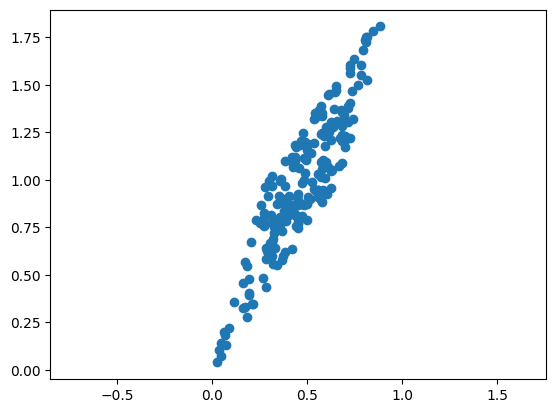

In [102]:
X = generate_and_plot_random_data()

We can see the data generally has a linear relationship. We can think of the principal axes as vectors that run along the data.

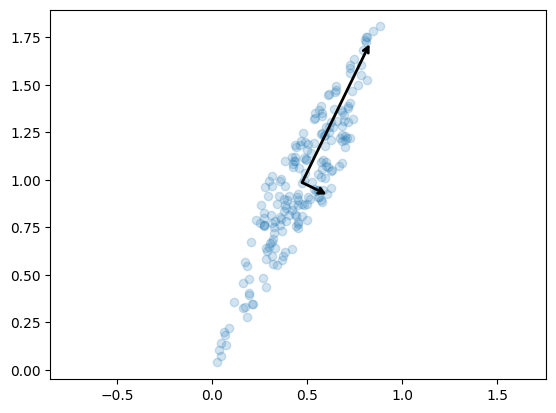

In [103]:
pca = PCA(n_components=2)
pca.fit(X)

graph_principal_components(X, pca)

These principal axes give us some idea about the relationship between the x and y features. It also gives us a way to "rank" the principal axes in order of importance. To understand how, think about collapsing all of the data on to only one of the principal axes -- which would lose more information about the data's pattern? 

This idea of collapsing the data onto the best principal axes fuels the use of PCA to reduce the dimension of data. Let's use PCA to reduce the dimensionality of the wine dataset and compare it to just using the first 2 features of the wine dataset. 

## PCA on Images - What are the "Core" Features of an Image?

Principal axes makes sense makes sense with continuous predictor variables, but what happens when we want to consider the "princpal axes" of an image? 

### Noise Filtering

A common task in computer vision is to remove noise (unwanted variation of brightness/color) from an image. This usually looks like blur or additional blotches from the wanted image. The idea to PCA for noise filtering is to first build the "core components" of the image (principal components), then systematically rebuild the fuzzy images with the principal component images. 

#### Imports/Functions for Example

In [95]:
from sklearn.datasets import load_digits
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

def plot_digits(data, rows_of_digits, columns_of_digits):
    fig, axes = plt.subplots(rows_of_digits, columns_of_digits, figsize=(10, 4),
                             subplot_kw={'xticks':[], 'yticks':[]},
                             gridspec_kw=dict(hspace=0.1, wspace=0.1))
    for i, ax in enumerate(axes.flat):
        ax.imshow(data[i].reshape(8, 8),
                  cmap='binary', interpolation='nearest',
                  clim=(0, 16))

def make_digits_fuzzy(data, random_state):
    rng = np.random.default_rng(random_state)
    rng.normal(10, 2)
    noisy_images = rng.normal(data, 4)
    return noisy_images

def plot_principal_components(pca, num_rows, num_cols):
    '''
        Make sure num_rows * num_cols < num_principal_axes
    '''
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(9, 4),
                            subplot_kw={'xticks':[], 'yticks':[]},
                            gridspec_kw=dict(hspace=0.1, wspace=0.1))
    for i, ax in enumerate(axes.flat):
        ax.imshow(pca.components_[i].reshape(8, 8), cmap='binary')

def plot_cumsum(pca, n_explained_var):
    '''  
        Choose a number of principal axes to see their explained variance, 
        between 0 and 64 inclusive
    '''
    cumsum_values = np.insert(np.cumsum(pca.explained_variance_ratio_), 0, 0) # Inserts 0 explained variance at 0 features
    plt.plot(cumsum_values)
    plt.xlabel('number of components')
    plt.ylabel('cumulative explained variance')

    explained_variance_for_n = round(np.cumsum(pca.explained_variance_ratio_)[n_explained_var-1], 3)
    plt.axvline(x=n_explained_var, color='red', linestyle='--', linewidth=2, label='Threshold')
    print(f'Explained Variance with {n_explained_var} Principal Axes: {explained_variance_for_n}')

#### Fuzzy Images

Check out the fuzzy written numbers below. Our goal is to remove some of the fuzz and any stray marks so we can more easily identify the written number. 

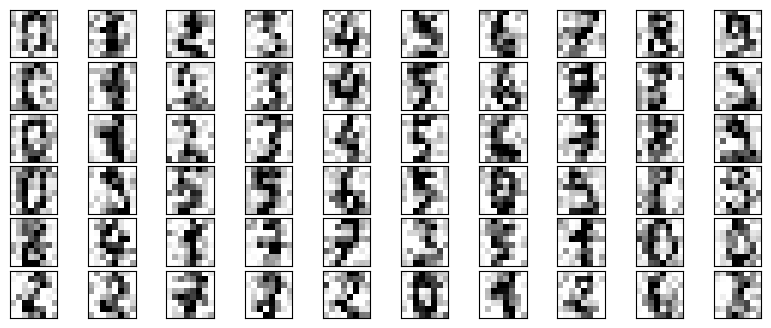

In [8]:
digits = load_digits()
fuzzy_data = make_digits_fuzzy(digits.data, random_state=30)
plot_digits(data=fuzzy_data, rows_of_digits=6, columns_of_digits=10)

Now let's see what mathematically are the "core components" of the images. We plot the first 30, but there are 64 total. 

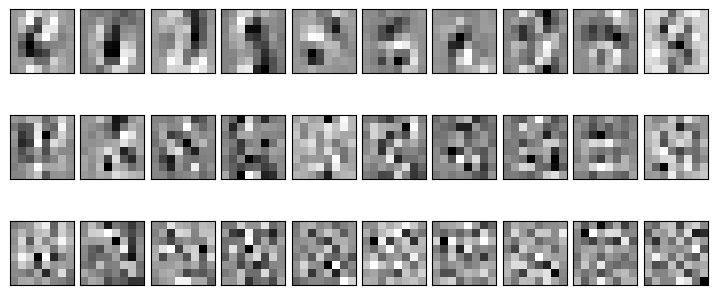

In [92]:
pca = PCA(n_components=64, svd_solver='randomized', random_state=30)
pca.fit(fuzzy_data)

plot_principal_components(pca, num_rows=3, num_cols=10)

Notice how the "core components" of the images are parts of numbers and not entire numbers themselves! Also notice how these principal axes start as large black marks of numbers and become more refined as it goes. 

We then use these core images to remove pixels that aren't part of these core images. 

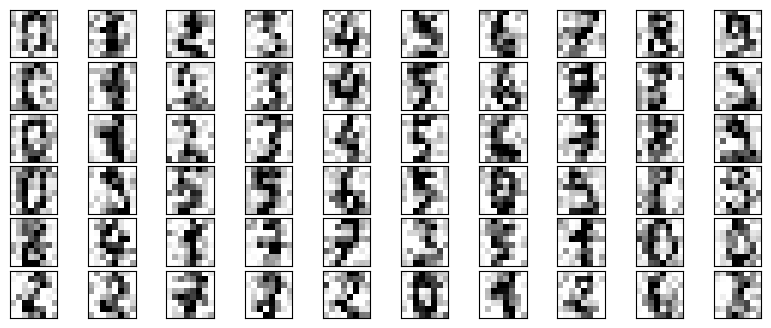

In [97]:
components = pca.transform(fuzzy_data) # Create principal axes
filtered = pca.inverse_transform(components) # Use principal axes to reconstruct images without fuzz
plot_digits(filtered, rows_of_digits=6, columns_of_digits=10)

No change! So what happened? 

**Since we used all 64 axes, we did not filter any noise out.** Let's consider how many axes to use. 

#### Determining Number of Principal Components to Keep

We either want to look for an "elbow" (a place where the gains suddenly flatten) or hit a target threshold. 

Explained Variance with 26 Principal Axes: 0.706


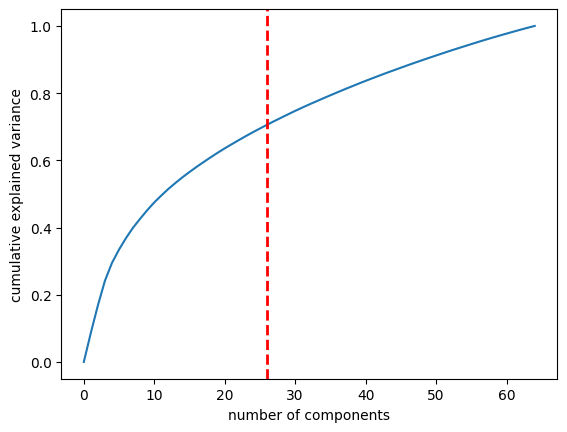

In [96]:
plot_cumsum(pca, 26)

No clear elbow, so let's consider a target threshold of 70% explained variance. *Consider how you would automate finding this threshold with code. To keep the example moving, we note it is 26.*

#### Final Result

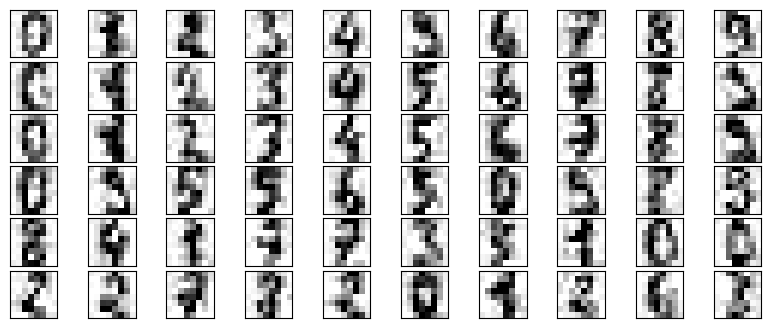

In [98]:
pca = PCA(n_components=26, svd_solver='randomized', random_state=30)
pca.fit(fuzzy_data)

components = pca.transform(fuzzy_data) # Create principal axes
filtered = pca.inverse_transform(components) # Use principal axes to reconstruct images without fuzz
plot_digits(filtered, rows_of_digits=6, columns_of_digits=10)

**Success!** While the main black marks are slightly more blurry, there is far less noise around the image. 

Try playing around with the number of principal components to keep and see how it impacts the final result. 